In [1]:
import os
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [3]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [4]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [5]:
auction_tracking

,time,_next_timeslot,_bids,_location_results
0,1,30,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
1,2,30,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
2,3,30,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
3,4,30,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
4,5,30,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
...,...,...,...,...
294,295,315,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
295,296,315,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
296,297,315,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."
297,298,315,"{'872664ca9ffffff': [(5, 0.0, 2), (1, 0.697530...","{'872664c1effffff': {1: (0, 0.0), 2: (0, 0.0)}..."


In [6]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [7]:
vehicle_tracking

,time,_fleet,_state,_current_state_of_charge
0,1,0,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
1,1,1,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
2,2,0,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
3,2,1,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
4,3,0,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
...,...,...,...,...
593,297,1,"[3, 3, 3, 2, 1, 1, 2, 2, 2, 1003, 2, 3, 2, 2, ...","[25.0, 25.0, 21.148560900376804, 47.5895569298..."
594,298,0,"[3, 3, 2, 1003, 2, 1003, 1, 2, 3, 5, 4, 5, 100...","[25.0, 25.0, 49.23942585776101, 49.18600537970..."
595,298,1,"[3, 3, 3, 2, 1001, 1, 2, 2, 2, 1003, 2, 3, 2, ...","[25.0, 25.0, 21.148560900376804, 47.5895569298..."
596,299,0,"[3, 3, 2, 2, 2, 1003, 1, 2, 3, 5, 4, 5, 1003, ...","[25.0, 25.0, 49.23942585776101, 48.73520955784..."


In [14]:
RECHARGE_THRESHOLD = 40 # ATTENTION: This is an approximation, we use dynamic ones per base region

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

Text(0.5, 1.0, '#Vehicles Fleet with Low SOC')

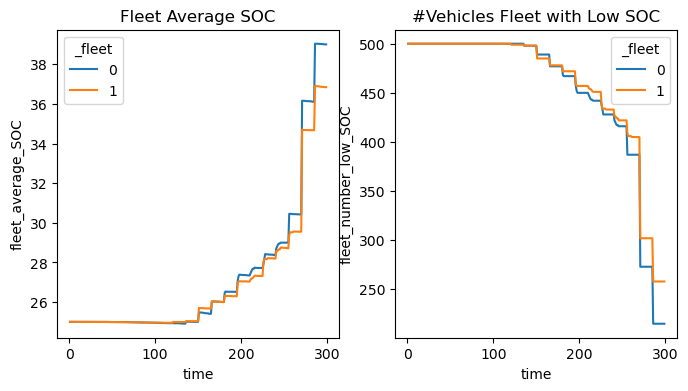

In [15]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (8, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title('#Vehicles Fleet with Low SOC')

In [10]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [11]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

Text(0.5, 1.0, 'CHARGING')

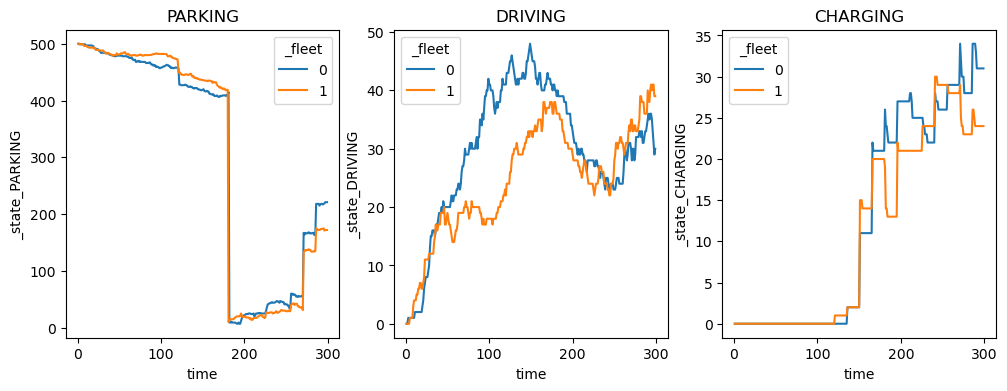

In [12]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[2])

ax[0].set_title('PARKING')
ax[1].set_title('DRIVING')
ax[2].set_title('CHARGING')

In [27]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [28]:
CHARGING_STATION_CAPACITY = 20

In [34]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

<Axes: xlabel='time', ylabel='system_wide_utilization'>

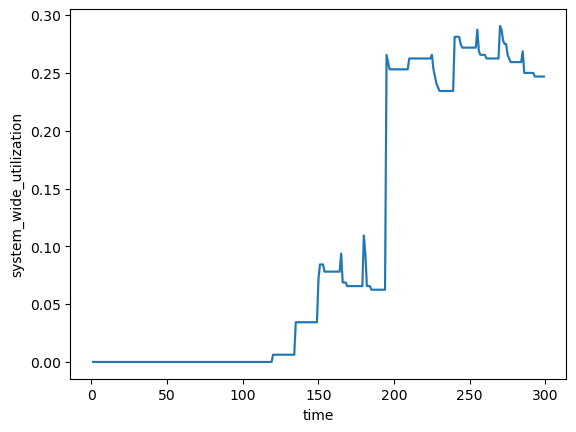

In [35]:
sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization')

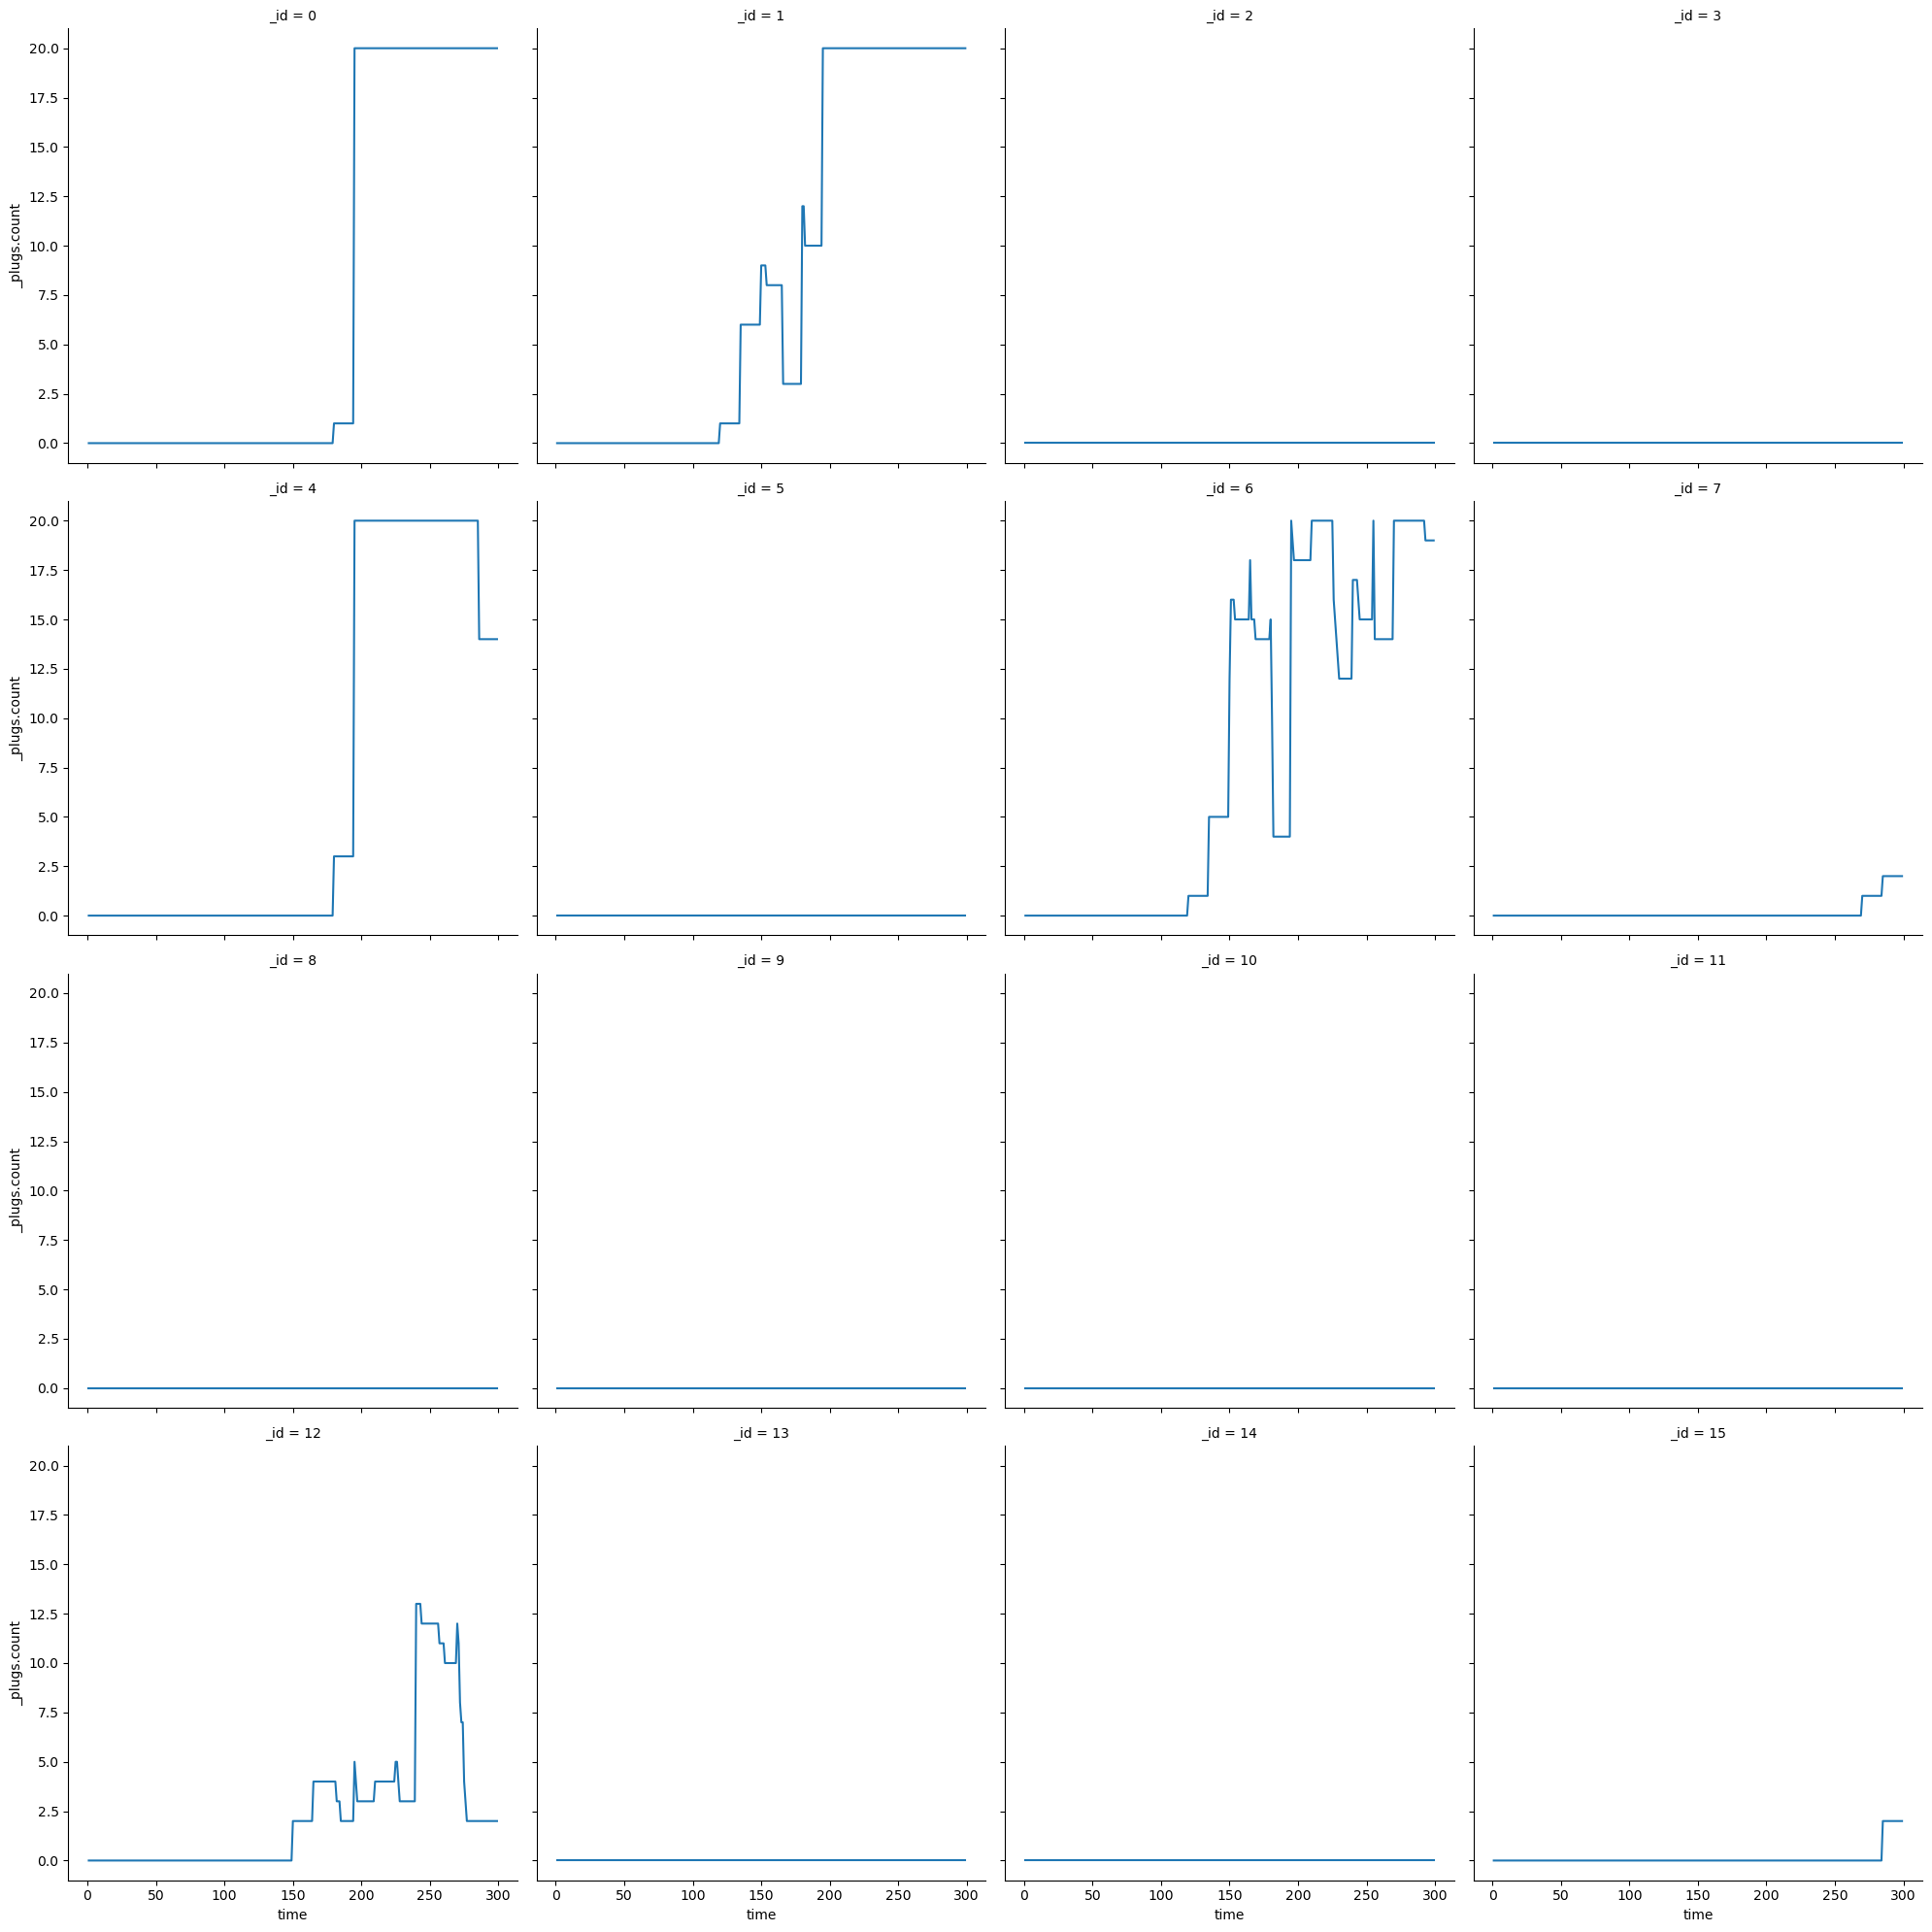

In [23]:
sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_id', kind='line', col_wrap=4)